In [102]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.plotting import plot_decision_regions

#                                                   Theory
```js
        Read "Random Forest.pdf" in the Theory folder.
```

#                                   In Classification, Random Forest is better than Decision Tree.

[[-0.09320235  0.31416035]
 [ 0.45456927  1.11851533]
 [ 0.11010588  0.05734025]
 [-0.29516739 -0.4879291 ]
 [-0.58675432  1.17293723]] 

[1 0 1 0 0]


<Axes: >

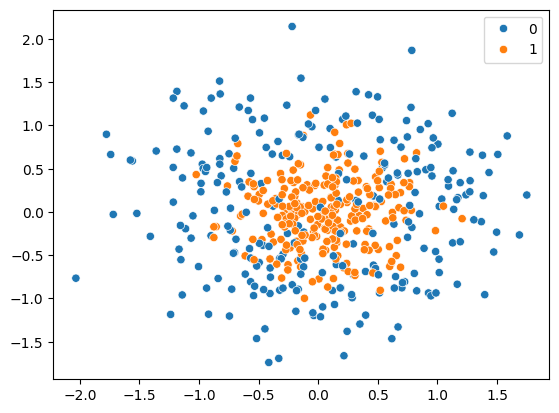

In [57]:
#                                              Dataset creation and visualization

X, y = make_circles(n_samples = 500, noise = 0.37, factor = 0.1, random_state = 42) # (500, 2), (500).
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

print(X[:5], '\n')
print(y[:5])

sns.scatterplot(x = X[:, 0], y = X[:, 1], hue = y) # The scatterplot of X, y.

For Decision Tree :
RMSE =  0.44721,
Accuracy =  0.80000.

For Random Forest :
RMSE =  0.41231,
Accuracy =  0.83000.


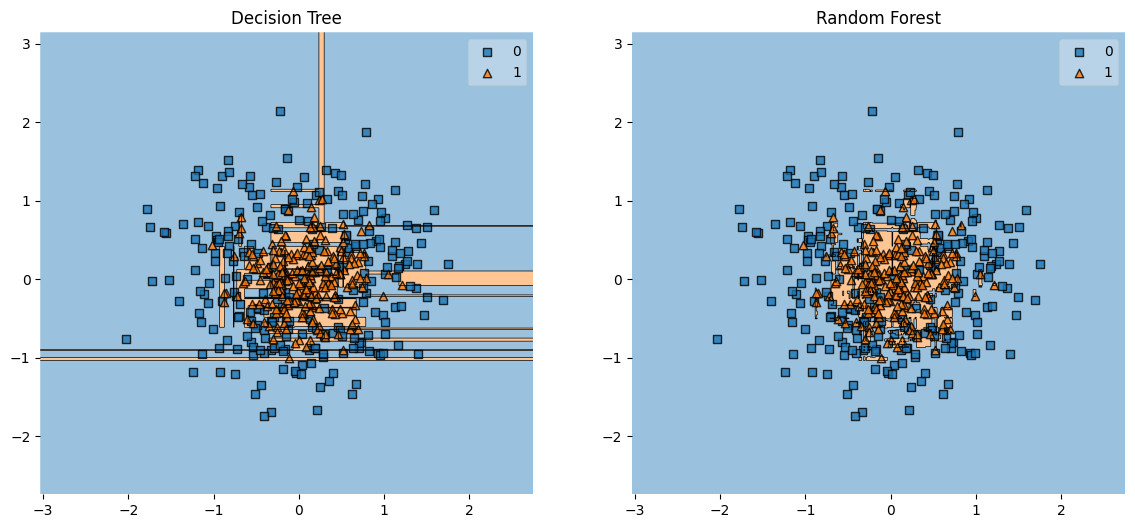

In [ ]:
#                           Comparing Decision Tree and Random Forest using accuracy, rmse and visualization.

dt = DecisionTreeClassifier(max_depth = None, random_state = 42) .fit(X = x_train, y = y_train)
rf = RandomForestClassifier(n_estimators = 10, max_depth = None, random_state = 42) .fit(X = x_train, y = y_train)

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (14, 6))
ax1 = plot_decision_regions(X = X, y = y, clf = dt, ax = axes[0])
ax1.set_title("Decision Tree")
ax2 = plot_decision_regions(X = X, y = y, clf = rf, ax = axes[1])
ax2.set_title("Random Forest")

print(f"""For Decision Tree :
RMSE = {root_mean_squared_error(y_true = y_test, y_pred = dt.predict(x_test)): .5f},
Accuracy = {accuracy_score(y_true = y_test, y_pred = dt.predict(x_test)): .5f}.""")

print(f"""\nFor Random Forest :
RMSE = {root_mean_squared_error(y_true = y_test, y_pred = rf.predict(x_test)): .5f},
Accuracy = {accuracy_score(y_true = y_test, y_pred = rf.predict(x_test)): .5f}.""")

explanation = """
Both Decision Tree and Random Forest used here with max_depth = None.

Decision Tree tried to capture all yellow points but Random Forest tried to put "region" so we can say "In that region all are
yellow and in other regions all are blue." So instead of catching every point, RF learning the patterns/regions of the points.
As a result, in terms of both accuracy and RMSE, Random Forest performs better without changing any parameter's default value.
"""

#                                   In Regression, Random Forest is better than Decision Tree.

<Axes: >

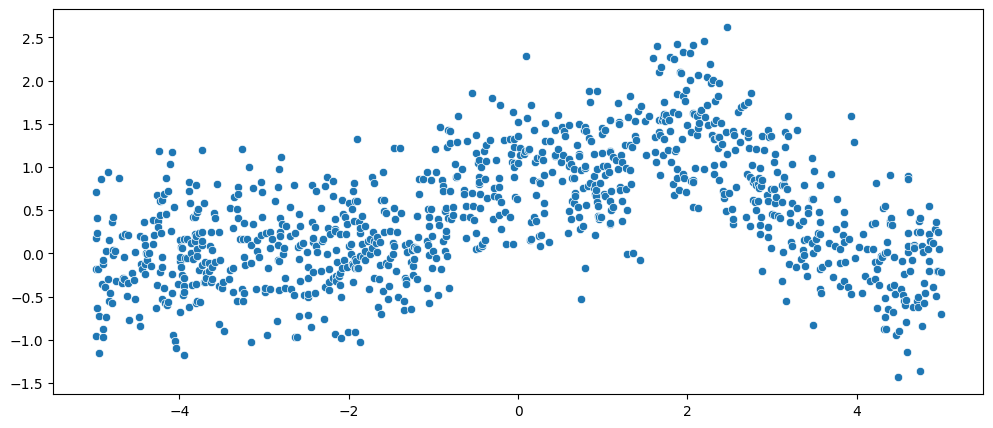

In [110]:
#                                              Dataset creation and visualization
# The below function is from https://github.com/campusx-official/100-days-of-machine-learning/blob/main/day65-random-forest/random_forest_demo.ipynb

def generate(n_samples, noise):
    X = np.random.rand(n_samples) * 10 - 5
    X = np.sort(X).ravel()
    y = np.exp(-X ** 2) + 1.5 * np.exp(-(X - 2) ** 2)\
        + np.random.normal(0.0, noise, n_samples)
    X = X.reshape((n_samples, 1))

    return X, y

X, y = generate(n_samples = 1000, noise = 0.5) # (1000, 1), (1000).
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

plt.figure(figsize = (12, 5))
sns.scatterplot(x = X.ravel(), y = y)

RMSE on Training = 0.0.
RMSE on Testing  = 0.7116054803715239.
Difference in error = 0.7116054803715239.


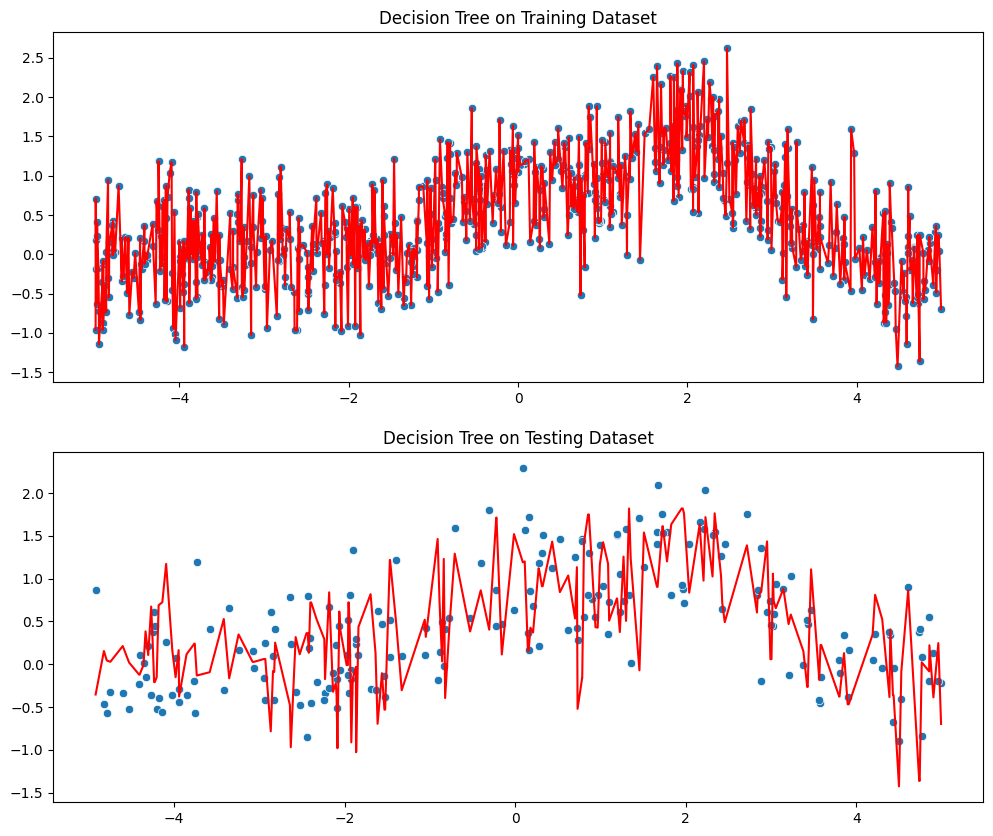

In [ ]:
#                           Decision Tree's rmse and visualization on training and testing data.

dt = DecisionTreeRegressor(max_depth = None, random_state = 42) .fit(X = x_train, y = y_train)

fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (12, 10))
ax1 = sns.scatterplot(x = x_train.ravel(), y = y_train, ax = axes[0])
sns.lineplot(x = x_train.ravel(), y = dt.predict(x_train), color = 'red', ax = axes[0])
ax1.set_title("Decision Tree on Training Dataset")

ax2 = sns.scatterplot(x = x_test.ravel(), y = y_test, ax = axes[1])
sns.lineplot(x = x_test.ravel(), y = dt.predict(x_test), color = 'red', ax = axes[1])
ax2.set_title("Decision Tree on Testing Dataset")

pred_train = root_mean_squared_error(y_true = y_train, y_pred = dt.predict(x_train))
pred_test  = root_mean_squared_error(y_true = y_test,  y_pred = dt.predict(x_test))
print(f"RMSE on Training = {pred_train}.")
print(f"RMSE on Testing  = {pred_test}.")
print(f"Difference in error = {abs(pred_train - pred_test)}.")

explanation = """
Decision Tree with max_depth = None, captured each training points, hence low bias. But performed very poor on
testing dataset, hence overfitting and high variance. The prediction error difference between training and testing is highhh.
"""

RMSE on Training = 0.24543044119287716.
RMSE on Testing  = 0.5915416699355729.
Difference in error = 0.34611122874269573.


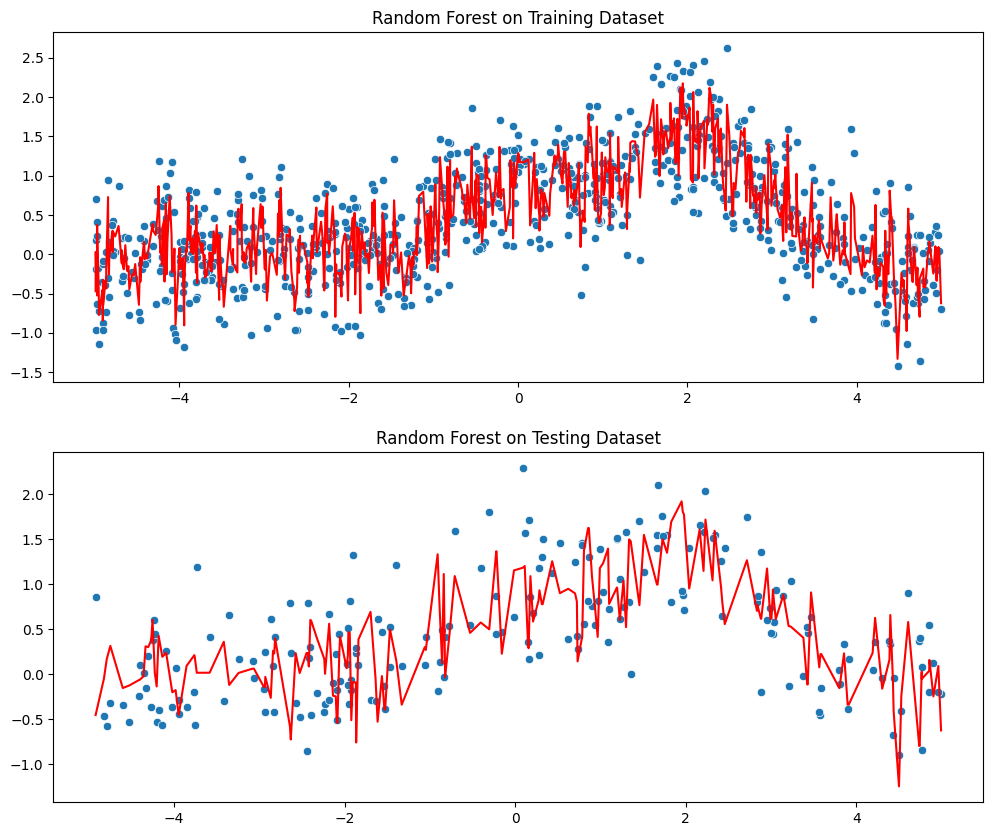

In [ ]:
#                           Decision Tree's rmse and visualization on training and testing data.

rf = RandomForestRegressor(n_estimators = 10, max_depth = None, random_state = 42) .fit(X = x_train, y = y_train)

fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (12, 10))
ax1 = sns.scatterplot(x = x_train.ravel(), y = y_train, ax = axes[0])
sns.lineplot(x = x_train.ravel(), y = rf.predict(x_train), color = 'red', ax = axes[0])
ax1.set_title("Random Forest on Training Dataset")

ax2 = sns.scatterplot(x = x_test.ravel(), y = y_test, ax = axes[1])
sns.lineplot(x = x_test.ravel(), y = rf.predict(x_test), color = 'red', ax = axes[1])
ax2.set_title("Random Forest on Testing Dataset")

pred_train = root_mean_squared_error(y_true = y_train, y_pred = rf.predict(x_train))
pred_test  = root_mean_squared_error(y_true = y_test,  y_pred = rf.predict(x_test))
print(f"RMSE on Training = {pred_train}.")
print(f"RMSE on Testing  = {pred_test}.")
print(f"Difference in error = {abs(pred_train - pred_test)}.")

explanation = """
Random Forest with max_depth = None, tried to capture the PATTERN of training points (hence low bias). That's why it also
performed good on testing dataset than decision tree, hence overfitting reduced and lower variance.

The prediction error difference between training and testing is 0.34 which is very lower than 0.711 by decision tree.

Without changing any parameter's default value, random forest performed better. With changing parameter's value it performs more
better.
"""